# 05.03 - HYPERPARAMETERS AND MODEL VALIDATION - EXERCISES (SOLUTIONS)

## IRIS

In [1]:

# Setup
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, validation_curve, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, classification_report, r2_score, mean_absolute_error)

# Data
iris = sns.load_dataset("iris")
X_cls = iris.drop(columns=["species"])
y_cls = iris["species"]

# For regression, follow the slides' simple setup: predict petal_length from three features
X_reg = iris[["sepal_width", "sepal_length", "petal_width"]]
y_reg = iris["petal_length"]


### 1. Holdout evaluation (`train_test_split`)

**Tasks:**
1. Split `X_reg, y_reg` into train/test (e.g., 80/20) with a fixed `random_state`.

2. Fit `LinearRegression` on the train set.

3. Report **R²** and **MAE** on the **test** set.


In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

lr = LinearRegression().fit(X_train, y_train)

y_hat = lr.predict(X_test)
print("Test R²:", r2_score(y_test, y_hat))
print("Test MAE:", mean_absolute_error(y_test, y_hat))

Test R²: 0.9603293155857664
Test MAE: 0.26051798462523856



### 2. Train/Test Split & Confusion Matrix (DecisionTreeClassifier)

**Tasks:**
1. Use `train_test_split` with `train_size=0.8`, `random_state=0` on `(X_cls, y_cls)`.
2. Fit `DecisionTreeClassifier(max_depth=1)` on the training portion.
3. Predict on the test set and compute: `accuracy`, `precision (weighted)`, `recall (weighted)`, `f1 (weighted)`.
4. Build the **confusion matrix** and show it both as raw numbers and as a heatmap.
5. Print a short **classification_report**.


ACC: 0.567  PREC: 0.759  REC: 0.567  F1: 0.463
Confusion matrix (raw):
 [[11  0  0]
 [ 0  0 13]
 [ 0  0  6]]


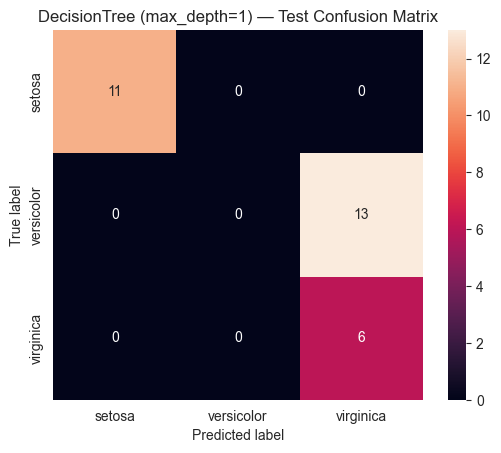

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        11
  versicolor        nan      0.00      0.00        13
   virginica       0.32      1.00      0.48         6

    accuracy                           0.57        30
   macro avg       0.66      0.67      0.49        30
weighted avg       0.76      0.57      0.46        30



In [3]:
# 1) Split
X_tr, X_tst, y_tr, y_tst = train_test_split(X_cls, y_cls, train_size=0.8, random_state=0)

# 2) Train model
clf = DecisionTreeClassifier(max_depth=1)
clf.fit(X_tr, y_tr)

# 3) Predict & metrics
y_pred = clf.predict(X_tst)

acc = accuracy_score(y_tst, y_pred)
prec = precision_score(y_tst, y_pred, average='weighted', zero_division=np.nan)
rec = recall_score(y_tst, y_pred, average='weighted')
f1 = f1_score(y_tst, y_pred, average='weighted')
print(f"ACC: {acc:.3f}  PREC: {prec:.3f}  REC: {rec:.3f}  F1: {f1:.3f}")

# 4) Confusion matrix
cm = confusion_matrix(y_tst, y_pred)
print("Confusion matrix (raw):\n", cm)

ax = sns.heatmap(cm, annot=True, square=True, cbar=True, xticklabels=clf.classes_, yticklabels=clf.classes_)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("DecisionTree (max_depth=1) — Test Confusion Matrix")
plt.show()

# 5) Classification report
print(classification_report(y_tst, y_pred, target_names=clf.classes_, zero_division=np.nan))



### 3. k-Fold Cross‑Validation (LinearRegression)

**Tasks:**
1. Instantiate `LinearRegression()`.
2. Perform K-fold cross-validation on the model using 5 folds and the R2-score as a scoring function on `(X_reg, y_reg)`.
3. Print the individual fold scores and their mean.
4. Compare this cross‑validated mean R² to the single holdout R² you would get from a simple 80/20 `train_test_split`.


In [4]:

lr = LinearRegression()
scores = cross_val_score(lr, X_reg, y_reg, cv=5, scoring='r2')
print("Fold R² scores:", np.round(scores, 4))
print("Mean R²:", scores.mean().round(4))

# Optional: compare to a single holdout
X_tr, X_tst, y_tr, y_tst = train_test_split(X_reg, y_reg, train_size=0.8, random_state=0)
lr_hold = LinearRegression().fit(X_tr, y_tr)
r2_hold = r2_score(y_tst, lr_hold.predict(X_tst))
print("Holdout R² (80/20):", round(r2_hold, 4))


Fold R² scores: [-0.9144  0.9544  0.5292  0.8769 -0.0226]
Mean R²: 0.2847
Holdout R² (80/20): 0.9513


// todo explanation

## Fold R² scores: [-0.9144, 0.9544, 0.5292, 0.8769, -0.0226]
- Two negative R² values → model performs worse than predicting the mean.
- Huge variance → model is highly sensitive to the training data.
- Mean R² = 0.2847 → on average, the model explains only ~28% of the variance. That’s not reliable.
## Holdout R² = 0.9513
- This looks excellent, but it might be misleading.
- Since it's just one split, it could be a lucky draw — especially if the data is not well shuffled or stratified



### 4. Validation Curve (DecisionTreeClassifier: `max_depth`)

**Tasks:**
1. Create a shallow range of depths, e.g. `param_range = np.arange(1, 8)`.
2. Run `validation_curve` on `DecisionTreeClassifier()` using `param_name='max_depth'`, 5 folds, and `X_cls, y_cls`.
3. Get the **mean** and **std** of the training and validation scores across folds for each depth.
4. Plot training vs validation mean scores against `max_depth`. Briefly comment in a markdown cell on where you see **underfitting** and **overfitting** tendencies.


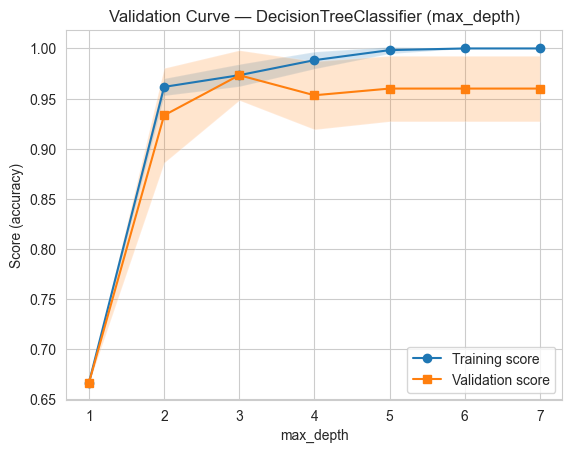

In [31]:
param_range = np.arange(1, 8)
dt = DecisionTreeClassifier()

train_scores, val_scores = validation_curve(
    dt, X=X_cls, y=y_cls, param_name='max_depth', param_range=param_range, cv=5
)

train_mean = train_scores.mean(axis=1)  # These scores show how well the model fits the training data
val_mean = val_scores.mean(axis=1)  #These scores show how well the model generalizes to unseen data.
train_std = train_scores.std(axis=1)
val_std = val_scores.std(axis=1)

plt.figure()
# Plots the mean training accuracy for each value of max_depth.
plt.plot(param_range, train_mean, marker='o', label='Training score')
plt.fill_between(param_range, train_mean - train_std, train_mean + train_std, alpha=0.2)
# Shades the ±1 standard deviation around the training mean.
plt.plot(param_range, val_mean, marker='s', label='Validation score')
plt.fill_between(param_range, val_mean - val_std, val_mean + val_std, alpha=0.2)
# Shades the ±1 standard deviation around the validation mean.
plt.xlabel("max_depth")
plt.ylabel("Score (accuracy)")
plt.title("Validation Curve — DecisionTreeClassifier (max_depth)")
plt.legend()
plt.show()



> **Comment:** Identify depths where the training score is high but validation drops (hint: potential **overfitting**), versus depths where both are low (hint: **underfitting**). Choose a reasonable depth for generalization.



### 5. Grid Search with Cross‑Validation + Final Test (DecisionTreeClassifier)

**Tasks:**
1. Split `(X_cls, y_cls)` into a **train/validate** set and a **holdout test** set using an 80/20 split.
2. Define a small grid, e.g. `{'criterion': ['gini', 'entropy', 'log_loss'], 'max_depth': range(1,7), 'min_samples_split': [2,3,4]}`.
3. Run `GridSearchCV(DecisionTreeClassifier(), param_grid=grid, cv=5)` on the **train/validate** set; `fit` and print `best_params_` and `best_score_`.
4. Refit a fresh `DecisionTreeClassifier` with `best_params_` on **all train/validate data**, then evaluate on the **holdout test** with accuracy/precision/recall/F1 and a confusion matrix heatmap. Optionally plot the small tree with `plot_tree`.


Best params: {'criterion': 'gini', 'max_depth': 2, 'min_samples_split': 2}
Best CV score: 0.95
score type: None
[TEST] ACC: 0.967  PREC: 0.969  REC: 0.967  F1: 0.966


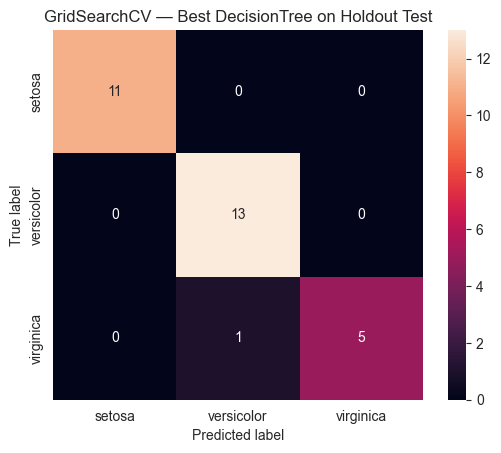

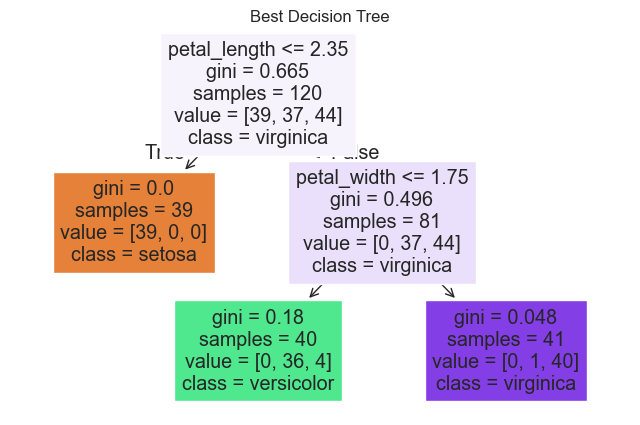

In [5]:

# 1) Split
X_tr, X_tst, y_tr, y_tst = train_test_split(X_cls, y_cls, train_size=0.8, random_state=0)

# 2) Grid
grid = {
    'criterion': ['gini', 'entropy', 'log_loss'],
    'max_depth': list(range(1, 7)),
    'min_samples_split': [2, 3, 4]
}

param_grid = {
    'max_depth': np.arange(1, 21),  # Controls tree depth (complexity)
    'min_samples_split': [2, 5, 10, 20, 50],  # Minimum samples to split a node
    'min_samples_leaf': [1, 5, 10, 20],  # Minimum samples at a leaf node
    'max_features': ['auto', 'sqrt', 'log2', None],  # Number of features to consider at each split
    'criterion': ['gini', 'entropy'],  # Split quality metric
    'splitter': ['best', 'random'],  # Split strategy
    'class_weight': [None, 'balanced']  # Handle class imbalance
}

# 3) GridSearchCV
search = GridSearchCV(DecisionTreeClassifier(), param_grid=grid, cv=5)
search.fit(X_tr, y_tr)
print("Best params:", search.best_params_)
print("Best CV score:", round(search.best_score_, 4))
print("score type:", search.scoring)  # None
#  the reason you're seeing score type: None is because you didn't explicitly set the scoring parameter in your GridSearchCV. When scoring=None, it defaults to using the estimator’s .score() method — for DecisionTreeClassifier, that means accuracy.


# 4) Final training on train/validate, then test
best_clf = DecisionTreeClassifier(**search.best_params_).fit(X_tr, y_tr)
y_pred = best_clf.predict(X_tst)

acc = accuracy_score(y_tst, y_pred)
prec = precision_score(y_tst, y_pred, average='weighted')
rec = recall_score(y_tst, y_pred, average='weighted')
f1 = f1_score(y_tst, y_pred, average='weighted')
print(f"[TEST] ACC: {acc:.3f}  PREC: {prec:.3f}  REC: {rec:.3f}  F1: {f1:.3f}")

cm = confusion_matrix(y_tst, y_pred)
ax = sns.heatmap(cm, annot=True, square=True, cbar=True, xticklabels=best_clf.classes_, yticklabels=best_clf.classes_)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("GridSearchCV — Best DecisionTree on Holdout Test")
plt.show()

# Optional: visualize the (usually small) tree
plt.figure(figsize=(8, 5))
plot_tree(best_clf, feature_names=X_cls.columns, class_names=best_clf.classes_, filled=True)
plt.title("Best Decision Tree")
plt.show()


### 6. Cross‑validation with a `Pipeline`

**Tasks:**
1. Create a `Pipeline` with `('scale', StandardScaler())` and `('lr', LinearRegression())`.

2. Use `cross_val_score` with `cv=5` (5‑fold) and `scoring='r2'`. Fit on X_reg, y_reg

3. Report the individual fold scores and their mean.

In [33]:
from sklearn.pipeline import Pipeline

pipe = Pipeline([
    ('scale', StandardScaler()),
    ('lr', LinearRegression())
])

scores = cross_val_score(pipe, X_reg, y_reg, cv=5, scoring='r2')
print("Fold R² scores:", np.round(scores, 4))
print("Mean R²:", scores.mean().round(4))

Fold R² scores: [-0.9144  0.9544  0.5292  0.8769 -0.0226]
Mean R²: 0.2847


![image](images/img_val_grid.png)

## CONCRETE

### Task 1 : Import libraries

 Import the necessary libraries (Import pandas, numpy, matplotlib, seaborn, and sklearn libraries)

In [6]:
#SOLUTION_START
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, validation_curve, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score
#SOLUTION_END

### Task 2 : Load the data

 We load the data again from the Concrete Compressive Strength Dataset Regression Notebook 'Concrete_Data.csv'.


In [7]:
#SOLUTION_START
df = pd.read_csv('./data/concrete_data.csv')
#SOLUTION_END

### Task 3 : Polynomial regression function

Create a function 'polynomial_regression' with 2 parameters: degree (default=2) and **kwargs. The function returns a polynomial model, constructed by a pipeline 
of 'PolynomialFeatures' (with degree as parameter and include_bias set to False) and 'LinearRegression' (with **kwargs as parameter). 
What is the goal of the **kwargs parameter and what does the ** operator do?

In [8]:
#SOLUTION_START
def polynomial_regression(degree=2, **kwargs):
    model = make_pipeline(PolynomialFeatures(degree, include_bias=False), LinearRegression(**kwargs))
    return model

#**kwargs is a way in Python to add flexibility to the possible parameters in a function. In this case you are now able to pass all LinearRegression parameters when calling the polynomial_regression function.
#SOLUTION_END

### Task 4 : Validation curves

Create the the target variable 'csMPa' (y) and the feature variable (X) with 'Cement', 'Water', and 'Age' as features.

In [9]:
#SOLUTION_START
X = df[['cement', 'water', 'age']]
y = df['csMPa']
#SOLUTION_END

Calculate the training and the validation R-squared scores for the polynomial regression models of degree 1 to 5. Use a cross-validation fold value of 5. 
Print the average scores over the different cross-validation folds for the different models.

In [17]:
#SOLUTION_START
# Define the range of degrees for the polynomial features
degree = np.arange(1, 6)
# Get validation curve scores
# Default score used by validation_curve is the one given by the .score() method of the model, so here R2
train_score, val_score = validation_curve(polynomial_regression(), X, y,
                                          param_name='polynomialfeatures__degree',
                                          param_range=degree,
                                          cv=5)
print(f'Train mean R2 scores      : {train_score.mean(axis=1)}')
print(f'Validation mean R2 scores : {val_score.mean(axis=1)}')

print(f'average train R2 score: {train_score.mean(axis=1)} ')
print(f'average validation R2 score: {val_score.mean(axis=1)} ')

#SOLUTION_END

Train mean R2 scores      : [0.4506524  0.60823382 0.71564606 0.75499469 0.76854597]
Validation mean R2 scores : [ 0.24111855  0.29499127  0.39302491  0.38160046 -4.62918507]
average train R2 score: [0.4506524  0.60823382 0.71564606 0.75499469 0.76854597] 
average validation R2 score: [ 0.24111855  0.29499127  0.39302491  0.38160046 -4.62918507] 


Draw the validation curve. Use the median of the scores over the different cross validation folds. What you think about (underfitting/overfitting)? Is it useful to use a more complex model?

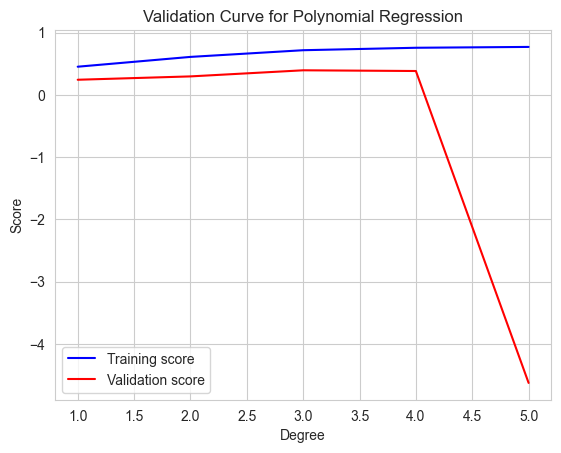

In [9]:
#SOLUTION_START
# Plot the validation curves
plt.plot(degree, np.mean(train_score, axis=1), color='blue', label='Training score')
plt.plot(degree, np.mean(val_score, axis=1), color='red', label='Validation score')
plt.legend()
plt.xlabel('Degree')
plt.ylabel('Score')
plt.title('Validation Curve for Polynomial Regression')
plt.show()
# As from degree 5, we see overfitting, so it is not usefull to use a more complex model
#SOLUTION_END

// todo explanation
## ✅ Is It a Good Model?
Not yet. Here's why:
- Best validation R² is ~0.39 at degree 3 → the model explains only ~39% of the variance on unseen data.
- Overfitting kicks in hard at higher degrees.
- Underfitting at degree 1–2, overfitting at degree 5 → the sweet spot is likely degree 3.

## 🔧 What You Can Do Next
- ✅ Stick with degree 3 — it gives the best validation performance.
- 🔁 Try regularization: use Ridge or Lasso instead of plain LinearRegression to reduce overfitting.
- 📉 Plot the validation curve to visualize the bias–variance tradeoff.
- 🧪 Try more features or feature engineering — maybe 'cement', 'water', and 'age' aren't enough to capture the complexity of csMPa.


### Task 5 : Grid Search

Use grid search to find the optimal polynomial model. Use a two-dimensional grid of model features, namely the polynomial degree from 1 to 10 and the flag telling us whether to fit the intercept. Use a cross-validation fold value of 7. Print the best parameters and the best scores (mean over the folds).

In [21]:
#SOLUTION_START
# Define the grid of parameters to search
# The keys are the names of the model parameters
# In case of a pipeline, these are preceded with the names of the submodels (lower case + __)
param_grid = {'polynomialfeatures__degree': np.arange(1, 11),
              'linearregression__fit_intercept': [True, False]}

# Setup the GridSearchCV
# Default score used by GridSearchCV is the one given by the .score() method of the model, so here R2
grid_search = GridSearchCV(polynomial_regression(), param_grid, cv=7, return_train_score=True)

# Fit the model
grid_search.fit(X, y)

# Get the best degree and corresponding score
best_params = grid_search.best_params_
best_score = grid_search.best_score_

print(f"Optimal Parameters: {best_params}")
print(f"Best Cross-Validated R2: {best_score:.3f}")
#SOLUTION_END

Optimal Parameters: {'linearregression__fit_intercept': True, 'polynomialfeatures__degree': np.int64(4)}
Best Cross-Validated R2: 0.396


In [29]:
results = grid_search.cv_results_
# print(results.keys())
train_scores = results['mean_train_score']
val_scores = results['mean_test_score']
print('Average train R2 scores:', np.round(train_scores, 2))
print('Average validation R2 scores:', np.round(val_scores, 2))

Average train R2 scores: [0.45 0.61 0.71 0.75 0.77 0.78 0.78 0.79 0.79 0.79 0.3  0.6  0.7  0.75
 0.76 0.77 0.78 0.79 0.79 0.78]
Average validation R2 scores: [ 2.30000000e-01  2.60000000e-01  2.10000000e-01  4.00000000e-01
 -1.45000000e+00 -1.60170000e+02 -1.14560000e+03 -1.85281300e+04
 -3.12843332e+06 -4.33362031e+07 -3.00000000e-02  2.50000000e-01
 -3.00000000e-02  3.50000000e-01 -1.82000000e+00 -1.66930000e+02
 -1.09100000e+03 -2.65370900e+04 -1.72029134e+07 -2.91588029e+08]
